# PFAS comparison 1 — XGBoost replacement: Physics-informed Bayesian Ridge
 Google Colab notebook | grouped 5-fold CV + Bayesian optimisation + uncertainty + SHAP

## 1. Install and import




In [1]:
%pip -q install optuna shap openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 10.6 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import shap
import joblib
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import mean_squared_error, mean_absolute_error

optuna.logging.set_verbosity(optuna.logging.WARNING)
np.random.seed(42)

## 2. Load Excel dataset

In [3]:
from google.colab import files
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
df = pd.read_excel(file_name, sheet_name='data')
df.head()

Saving AFFF_data_final_20240308.xlsx to AFFF_data_final_20240308.xlsx


,Membrane,MWCO (Da),Isoelectric point,Water contact angle,PFAS,Mw,SMILES,Compound size (Å),log Kow,pKa,Initial concentration (ng/L),IS (mM),Pressure (psi),pH,Removal_rate,ref_ID,ref
0,NF90,118,3.28,52.9,PFBA,214,C(=O)(C(C(C(F)(F)F)(F)F)(F)F)[O-],3.628016,-1.22,0.37,287.925,10.0,185.0,7.0,81.961093,1,exp
1,NF90,118,3.28,52.9,PFPeA,264,C(=O)(C(C(C(C(F)(F)F)(F)F)(F)F)(F)F)[O-],4.015968,-0.52,0.34,513.900,10.0,185.0,7.0,89.863274,1,exp
2,NF90,118,3.28,52.9,PFBS,300,C(C(C(F)(F)S(=O)(=O)[O-])(F)F)(C(F)(F)F)(F)F,3.992443,0.25,-3.31,4247.025,10.0,185.0,7.0,98.819583,1,exp
3,NF90,118,3.28,52.9,PFHxA,314,C(=O)(C(C(C(C(C(F)(F)F)(F)F)(F)F)(F)F)(F)F)[O-],4.128813,0.18,0.32,2275.425,10.0,185.0,7.0,98.270808,1,exp
4,NF90,118,3.28,52.9,PFPeS,350,C(C(C(F)(F)F)(F)F)(C(C(F)(F)S(=O)(=O)[O-])(F)F...,4.317291,0.95,-3.32,3333.175,10.0,185.0,7.0,98.560089,1,exp


## 3. Preprocess the experimental variables

In [4]:
df = df.rename(columns={
    'MWCO (Da)': 'MWCO',
    'Isoelectric point': 'IEP',
    'Water contact angle': 'CA',
    'Compound size (Å)': 'Size',
    'Initial concentration (ng/L)': 'Init_conc',
    'IS (mM)': 'IS',
    'Pressure (psi)': 'Pres'
})

df['ref_ID'] = df['ref_ID'].astype(str)
df['charge'] = -1 / (1 + 10 ** np.clip(df['pKa'] - df['pH'], -100, 100))
df['charge_product'] = (df['IEP'] - df['pH']) * df['charge']
df['Init_conc'] = df['Init_conc'] / df['Mw']
df['log_conc'] = np.log10(df['Init_conc'].clip(lower=1e-8))
df['MWCO_log'] = np.log1p(df['MWCO'])
df['pressure_log'] = np.log1p(df['Pres'])
df['Mw_by_MWCO'] = df['Mw'] / df['MWCO']
df['molecular_size_ratio'] = df['Size'] / np.sqrt(df['MWCO'])

train = df[df['ref_ID'] != '1'].copy()
test = df[df['ref_ID'] == '1'].copy()
train['group'] = train['ref_ID'] + '_' + train['PFAS']

print('Training observations:', len(train))
print('Experimental test observations:', len(test))

Training observations: 457
Experimental test observations: 77


## 4. Select features and create grouped CV


In [5]:
features = [
    'MWCO', 'CA', 'Size', 'log Kow', 'log_conc',
    'Pres', 'IS', 'charge_product', 'IEP', 'pH',
    'pKa', 'Mw', 'MWCO_log', 'pressure_log',
    'Mw_by_MWCO', 'molecular_size_ratio'
]

X_train = train[features]
y_train = train['Removal_rate']
X_test = test[features]
y_test = test['Removal_rate']
groups = train['group']

cv = GroupKFold(n_splits=5)
folds = list(cv.split(X_train, y_train, groups))

## 5. Grouped 5-fold CV + Bayesian hyperparameter search


In [6]:
N_TRIALS = 15

def make_model(params):
    return make_pipeline(
        StandardScaler(),
        BayesianRidge(
            alpha_1=params['alpha_1'],
            alpha_2=params['alpha_2'],
            lambda_1=params['lambda_1'],
            lambda_2=params['lambda_2']
        )
    )

def objective(trial):
    params = {
        'alpha_1': trial.suggest_float('alpha_1', 1e-9, 1e-3, log=True),
        'alpha_2': trial.suggest_float('alpha_2', 1e-9, 1e-3, log=True),
        'lambda_1': trial.suggest_float('lambda_1', 1e-9, 1e-3, log=True),
        'lambda_2': trial.suggest_float('lambda_2', 1e-9, 1e-3, log=True)
    }
    predictions = np.zeros(len(train))
    for train_ids, val_ids in folds:
        model = make_model(params)
        model.fit(X_train.iloc[train_ids], y_train.iloc[train_ids])
        predictions[val_ids] = model.predict(X_train.iloc[val_ids])
    return np.sqrt(mean_squared_error(y_train, predictions))

study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=N_TRIALS)

print('Best grouped CV RMSE:', round(study.best_value, 3))
print('Best hyperparameters:', study.best_params)

Best grouped CV RMSE: 8.548
Best hyperparameters: {'alpha_1': 1.1121853473062499e-07, 'alpha_2': 1.015907003477362e-05, 'lambda_1': 0.0009373661684574769, 'lambda_2': 1.0706787630075477e-05}


## 6. Train on all 457 observations, then evaluate the 77 test observations once in this run

In [7]:
model = make_model(study.best_params)
model.fit(X_train, y_train)

train_pred = np.clip(model.predict(X_train), 0, 100)
test_pred = np.clip(model.predict(X_test), 0, 100)

train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
train_mae = mean_absolute_error(y_train, train_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_mae = mean_absolute_error(y_test, test_pred)

results = pd.DataFrame({
    'Model': ['XGBoost (published)', 'Bayesian Ridge (new)'],
    'Test RMSE (%)': [8.4, test_rmse],
    'Test MAE (%)': [6.4, test_mae],
    'Source': ['Original paper', 'This notebook']
})

print('Training RMSE:', round(train_rmse, 3))
print('Training MAE:', round(train_mae, 3))
print('External test RMSE:', round(test_rmse, 3))
print('External test MAE:', round(test_mae, 3))
display(results)

Training RMSE: 6.466
Training MAE: 4.431
External test RMSE: 7.158
External test MAE: 5.473


,Model,Test RMSE (%),Test MAE (%),Source
0,XGBoost (published),8.40000,6.400000,Original paper
1,Bayesian Ridge (new),7.15776,5.472818,This notebook


## 7. Uncertainty (Bayesian predictive standard deviation)

Observed 95% interval coverage: 93.5 %


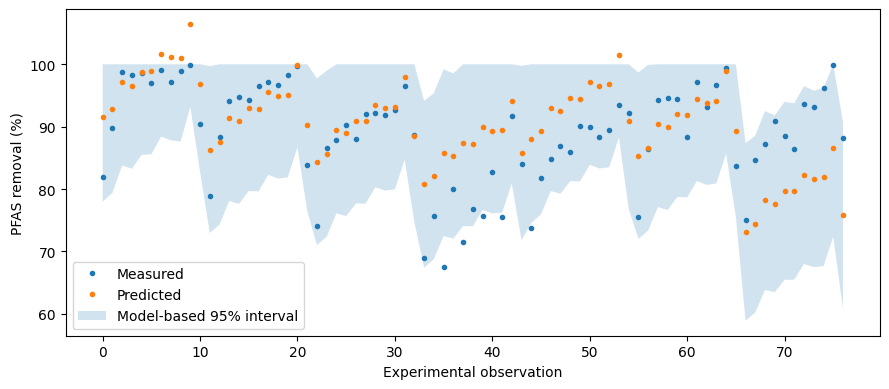

In [8]:
scaled_test = model.named_steps['standardscaler'].transform(X_test)
mean, std = model.named_steps['bayesianridge'].predict(scaled_test, return_std=True)
lower = np.clip(mean - 1.96 * std, 0, 100)
upper = np.clip(mean + 1.96 * std, 0, 100)
coverage = np.mean((y_test >= lower) & (y_test <= upper)) * 100
print('Observed 95% interval coverage:', round(coverage, 1), '%')

plt.figure(figsize=(9, 4))
plt.plot(y_test.to_numpy(), '.', label='Measured')
plt.plot(mean, '.', label='Predicted')
plt.fill_between(np.arange(len(test)), lower, upper, alpha=0.2, label='Model-based 95% interval')
plt.xlabel('Experimental observation')
plt.ylabel('PFAS removal (%)')
plt.legend()
plt.tight_layout()
plt.savefig('bayesian_intervals.png', dpi=200)
plt.show()

## 8. SHAP explanation of the Bayesian Ridge model

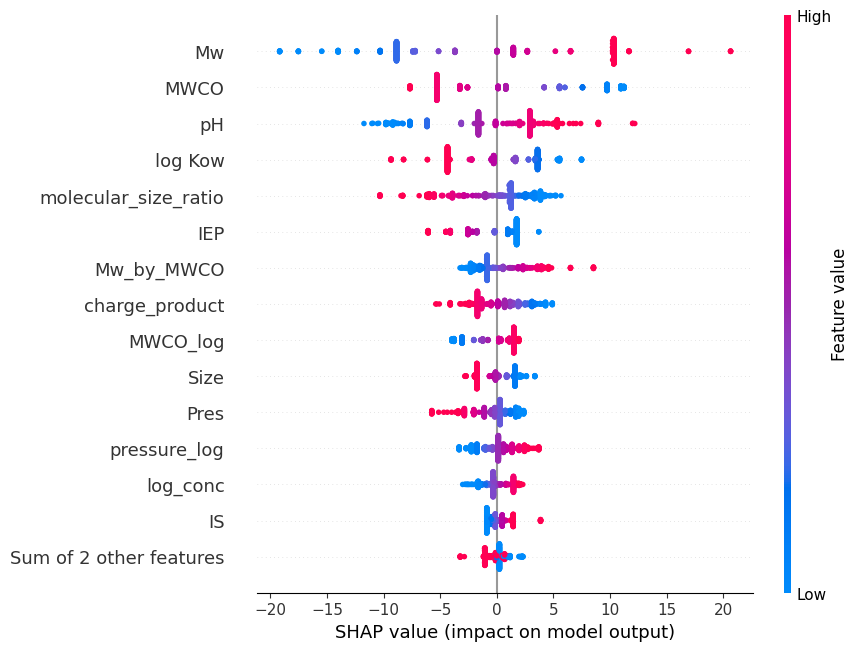

In [9]:
scaled_train = model.named_steps['standardscaler'].transform(X_train)
explainer = shap.Explainer(model.named_steps['bayesianridge'], scaled_train, feature_names=features)
shap_values = explainer(scaled_train)
shap.plots.beeswarm(shap_values, max_display=15, show=True)

## 9. Predictions and exports

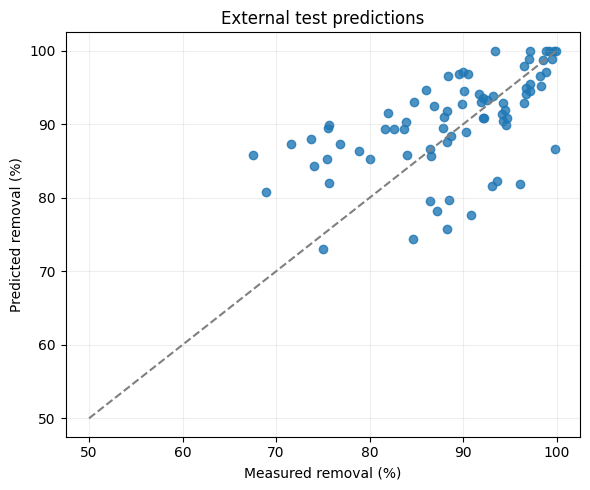

In [10]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, test_pred, alpha=0.8)
plt.plot([50, 100], [50, 100], '--', color='gray')
plt.xlabel('Measured removal (%)')
plt.ylabel('Predicted removal (%)')
plt.title('External test predictions')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig('test_predictions.png', dpi=200)
plt.show()